In [2]:
import os
import pandas as pd
import psycopg
from dotenv import load_dotenv
import matplotlib.pyplot as plt

In [3]:
load_dotenv("../.env")

query = """
    SELECT m.*, h.name AS home_team, a.name AS away_team,
           o.close_home, o.close_draw, o.close_away
    FROM matches m
    JOIN teams h ON m.home_team_id = h.team_id
    JOIN teams a ON m.away_team_id = a.team_id
    LEFT JOIN odds o ON m.match_id = o.match_id
"""

with psycopg.connect(os.environ["DATABASE_URL"]) as conn:
    rows = conn.execute(query)
    columns = [c.name for c in rows.description]
    df = pd.DataFrame(rows.fetchall(), columns=columns)

df.shape

(10510, 18)

In [5]:
rates = df.groupby("league")["result"].value_counts(normalize=True).unstack()
rates

result,A,D,H
league,,,
E0,0.319906,0.237705,0.442389
E1,0.301442,0.266506,0.432051


In [8]:
df["total_goals"] = df["home_goals"] + df["away_goals"]
avg_goals_game_seasone = df.groupby("season")["total_goals"].mean()
avg_goals_game_seasone

season
1516    2.535408
1617    2.687768
1718    2.604077
1819    2.730687
1920    2.672747
2021    2.465665
2122    2.635193
2223    2.603004
2324    2.924893
2425    2.648069
2526    2.664163
2627    2.852713
Name: total_goals, dtype: float64

In [11]:
df["home_win"] = df["result"] == "H"
home_wins_20_21 = df.groupby("season")["home_win"].mean()
home_wins_20_21

season
1516    0.412017
1617    0.481760
1718    0.440987
1819    0.451717
1920    0.431330
2021    0.398069
2122    0.438841
2223    0.440987
2324    0.451717
2425    0.437768
2526    0.420601
2627    0.410853
Name: home_win, dtype: float64

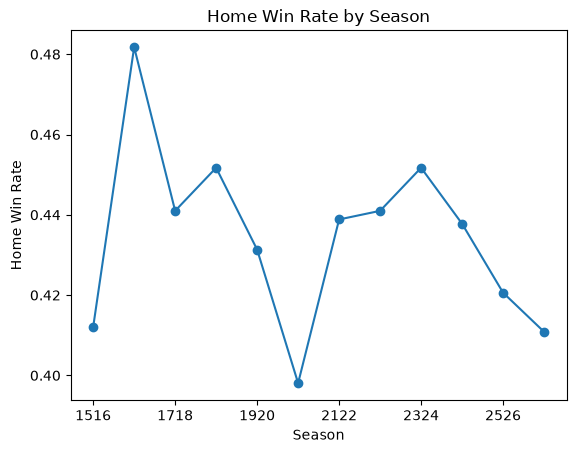

In [10]:
home_rate = df.groupby("season")["home_win"].mean()

home_rate.plot(marker="o")
plt.title("Home Win Rate by Season")
plt.xlabel("Season")
plt.ylabel("Home Win Rate")
plt.show()